# Day 81: Multivariable regression and valuation model

You are an analyst at a real estate development company in Boston in the 1970s. The company wants a price estimate for a residential project, based on the number of rooms, the distance to employment centres, how poor the area is, the number of students per teacher and similar characteristics. This notebook follows the project's seven steps and calls the functions of the `boston_valuation` package.

Install the notebook extra first: `python -m pip install -e ".[notebook]"`.

# Step 1: Goals and data exploration

In [1]:
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.core.pylabtools import print_figure
from matplotlib.figure import Figure

# The package draws with the Agg backend, so show every returned Figure as a PNG.
png = get_ipython().display_formatter.formatters["image/png"]
png.for_type(
    Figure,
    lambda figure: print_figure(figure, "png", dpi=100, bbox_inches="tight"),
)
plt.rcParams["figure.max_open_warning"] = 0

In [2]:
from boston_valuation.domain import descriptive, exploration
from boston_valuation.infrastructure.csv_loader import load_data
from boston_valuation.presentation.charts import descriptive_table_figure

data = load_data()
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


## Preliminary exploration

How many rows and columns are there, what are the columns called, and is there anything missing or duplicated?

In [3]:
print("Shape:", exploration.table_shape(data))
print("Columns:", exploration.column_names(data))
print("NaN values:", exploration.has_nan_values(data))
print("Duplicates:", exploration.has_duplicates(data))

Shape: (506, 14)
Columns: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'PRICE']
NaN values: False
Duplicates: False


In [4]:
exploration.first_rows(data)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [5]:
exploration.last_rows(data)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,80.8,2.5050,1.0,273.0,21.0,396.90,7.88,11.9


## Descriptive statistics

The average number of students per teacher, the average price (in thousands of dollars), the two values of the Charles River dummy `CHAS` and the range of rooms per dwelling.

In [6]:
print("Students per teacher:", round(descriptive.average_students_per_teacher(data), 2))
print("Average price ($1000s):", round(descriptive.average_price(data), 2))
print("Average price ($):", round(descriptive.average_price_in_dollars(data)))
print("CHAS min and max:", descriptive.river_value_range(data))
print("Tracts away from / next to the river:")
print(descriptive.river_counts(data))
print("Rooms min and max:", descriptive.room_range(data))

Students per teacher: 18.46
Average price ($1000s): 22.53
Average price ($): 22533
CHAS min and max: (0.0, 1.0)
Tracts away from / next to the river:
CHAS
0    471
1     35
Name: count, dtype: int64
Rooms min and max: (3.561, 8.78)


In [7]:
descriptive.descriptive_statistics(data)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


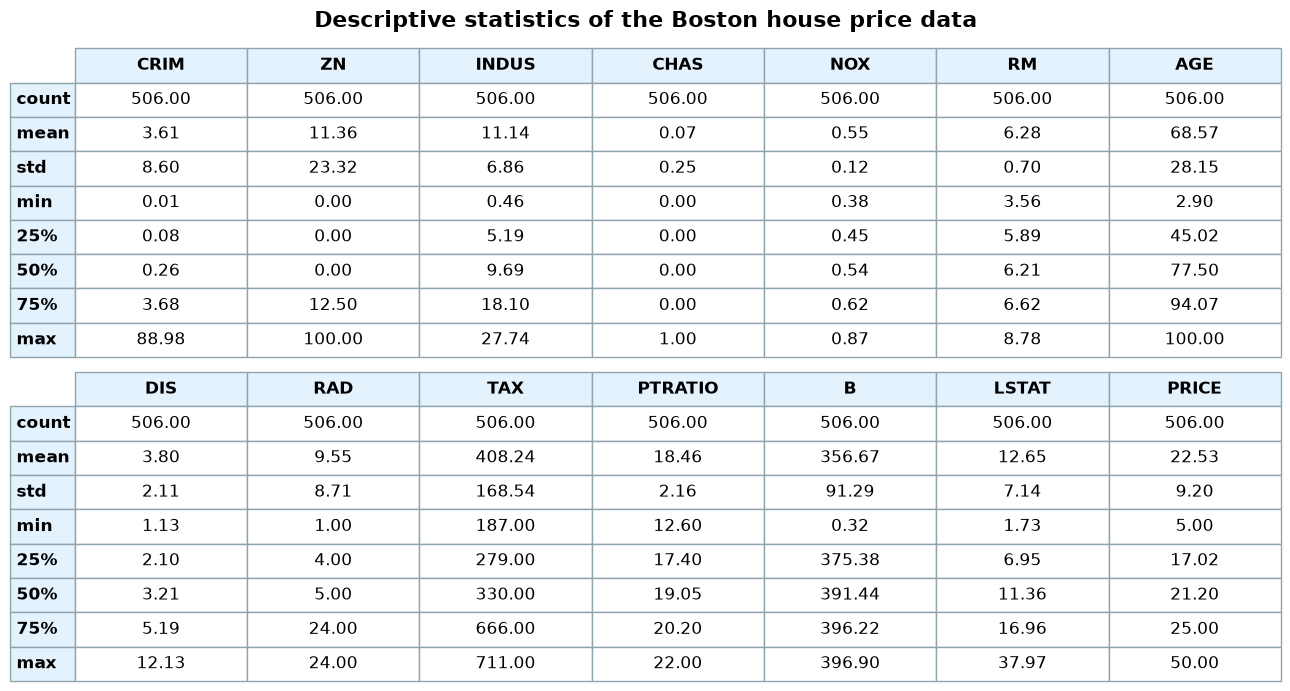

In [8]:
figure = descriptive_table_figure(data)
figure

# Step 2: Feature distributions

Look at one feature at a time: the shape of the price, the distance to the employment centres, the rooms and the highway access, and how many homes border the Charles River.

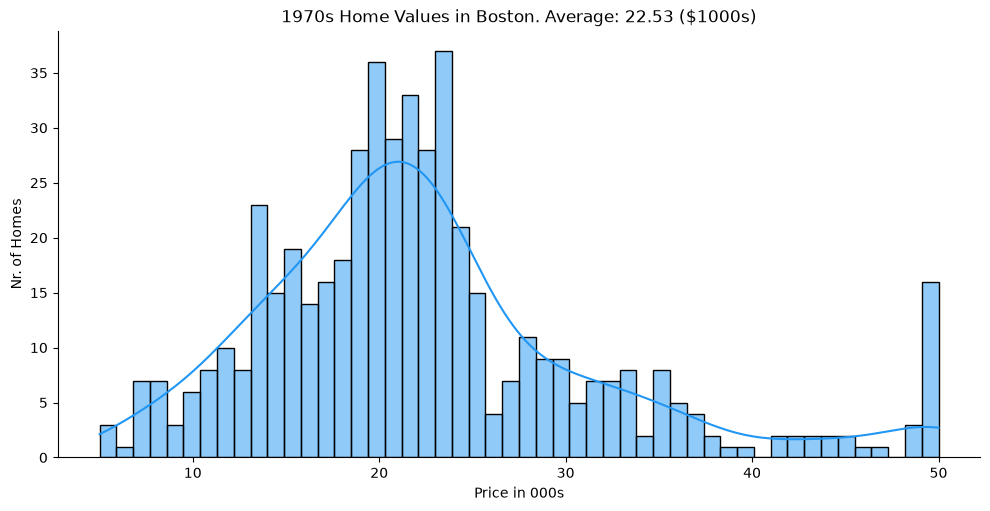

In [9]:
from boston_valuation.presentation.distribution_charts import (
    distance_distribution_figure,
    highway_access_figure,
    price_distribution_figure,
    river_bar_chart,
    rooms_distribution_figure,
)

price_distribution_figure(data)

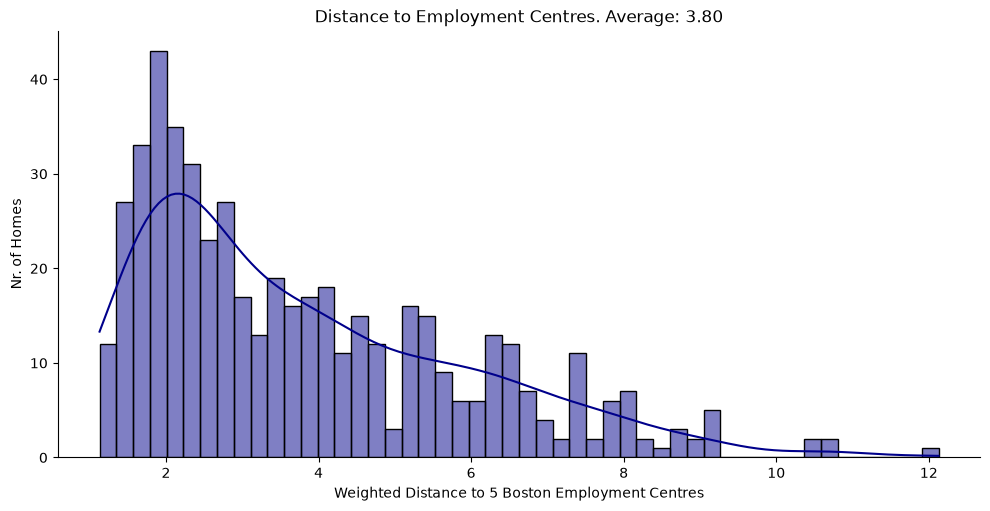

In [10]:
distance_distribution_figure(data)

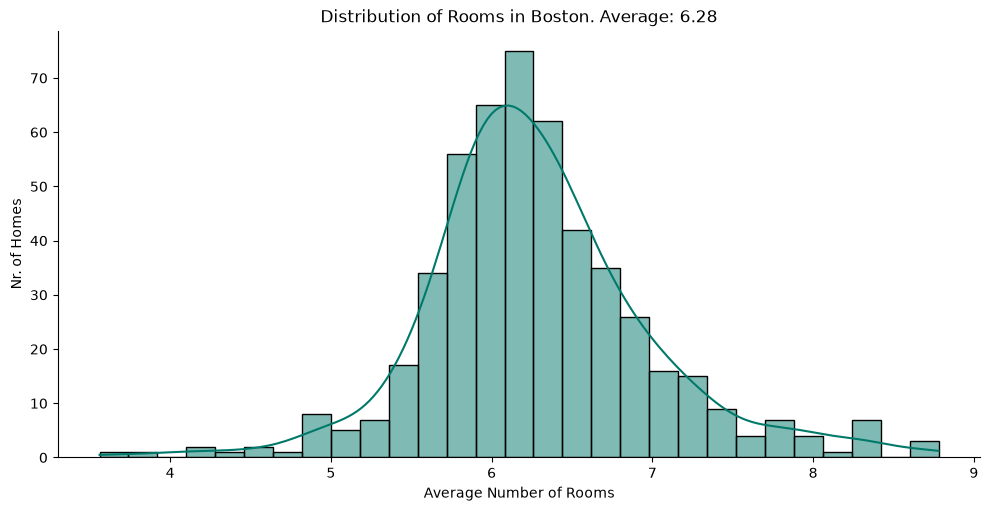

In [11]:
rooms_distribution_figure(data)

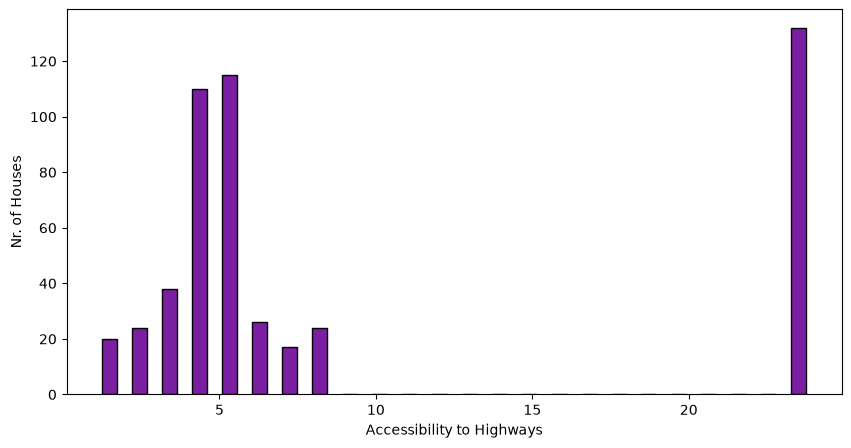

In [12]:
highway_access_figure(data)

`RAD` only takes the values 1 to 8 and 24, so the bars have gaps. The river dummy is a bar chart of two counts.

In [13]:
river_bar_chart(data)

# Step 3: Relationships in the data

Before modelling, predict what you expect: does pollution (`NOX`) rise or fall with the distance to employment (`DIS`)? What do the rooms (`RM`) and the poverty of an area (`LSTAT`) do to the price? Then check. A pair plot of all 14 columns can take a minute or two, so this notebook draws it for four columns.

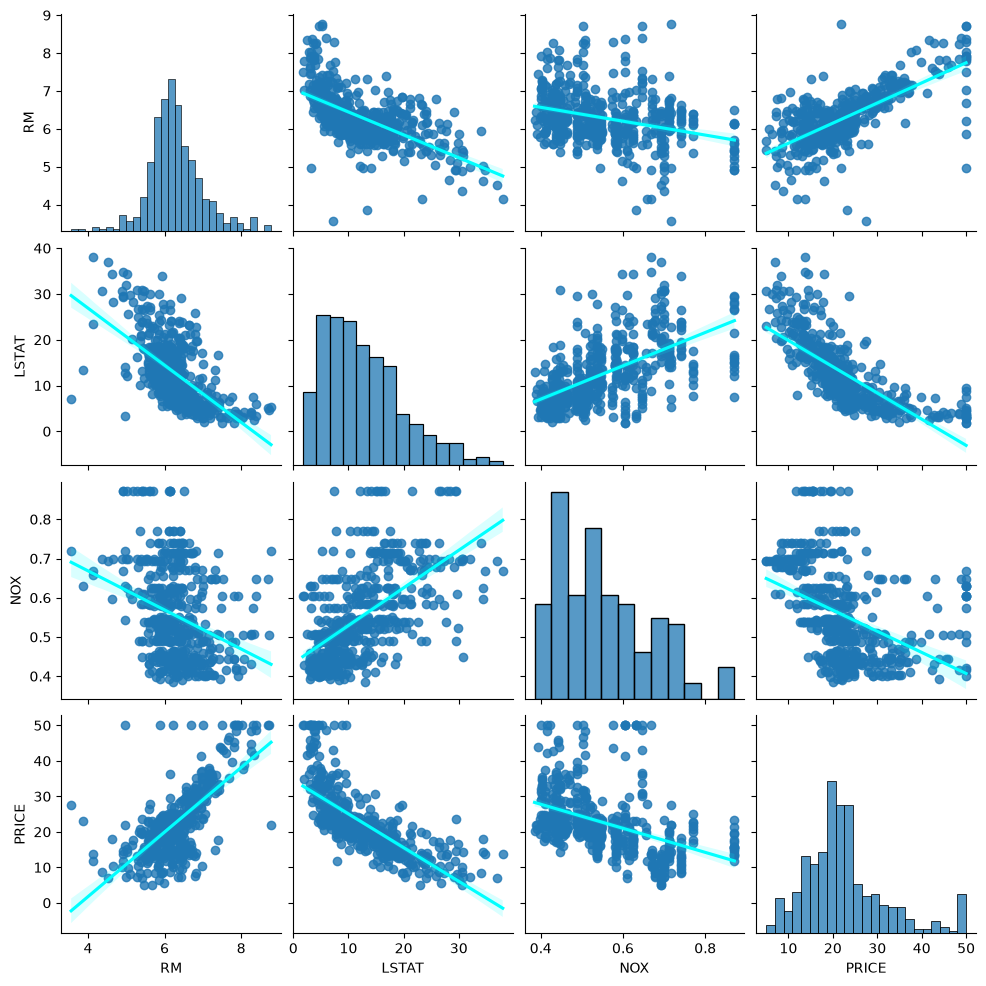

In [14]:
from boston_valuation.domain import relationships
from boston_valuation.presentation.relationship_charts import (
    distance_pollution_figure,
    pair_plot_figure,
    pollution_industry_figure,
    poverty_price_figure,
    poverty_rooms_figure,
    rooms_price_figure,
)

pair_plot_figure(data, columns=["RM", "LSTAT", "NOX", "PRICE"], regression_line=True)

Pass `columns=None` to draw the pair plot of every column, as in the course.

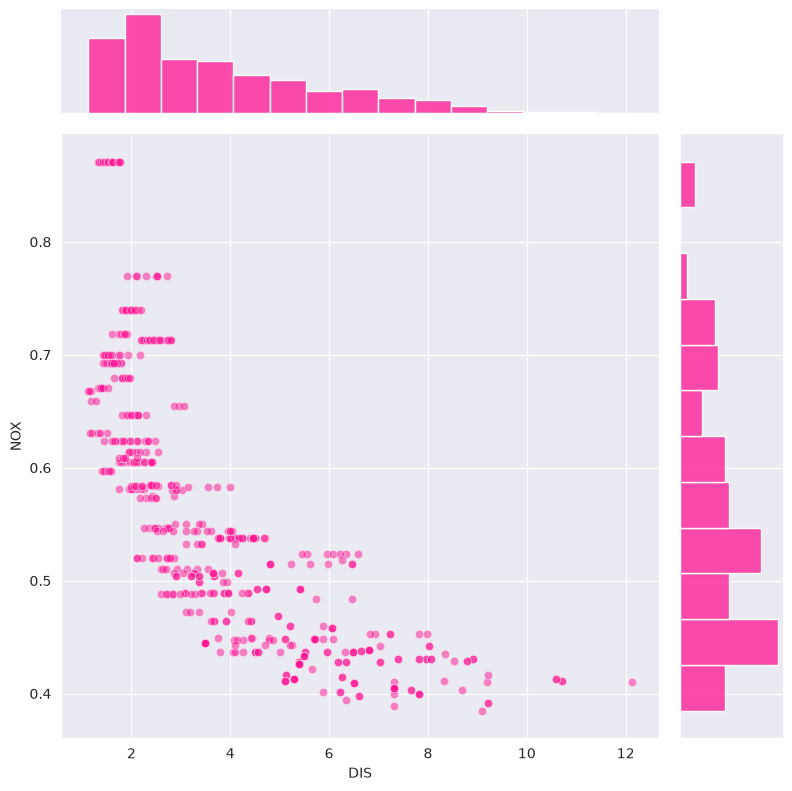

In [15]:
distance_pollution_figure(data)

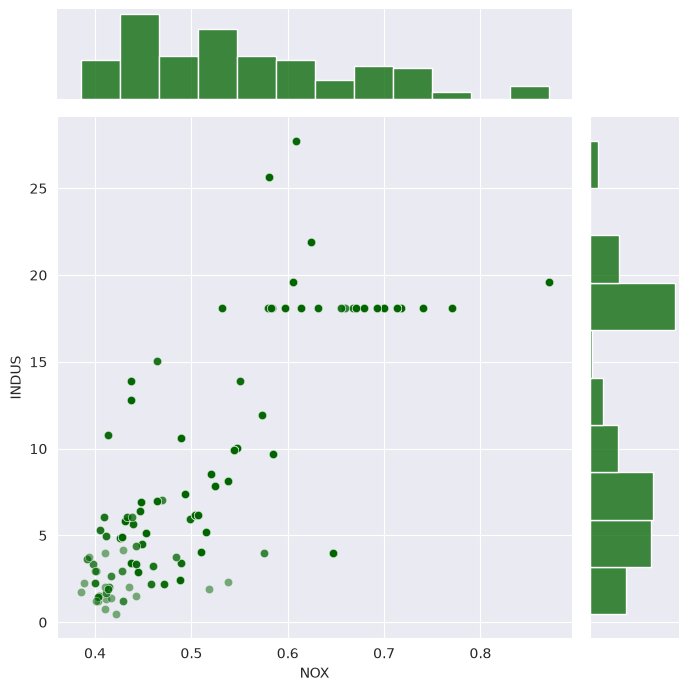

In [16]:
pollution_industry_figure(data)

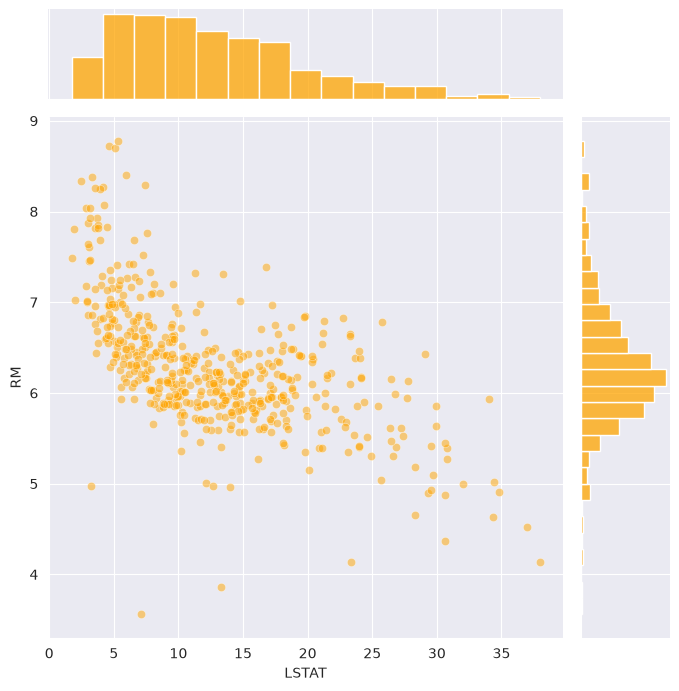

In [17]:
poverty_rooms_figure(data)

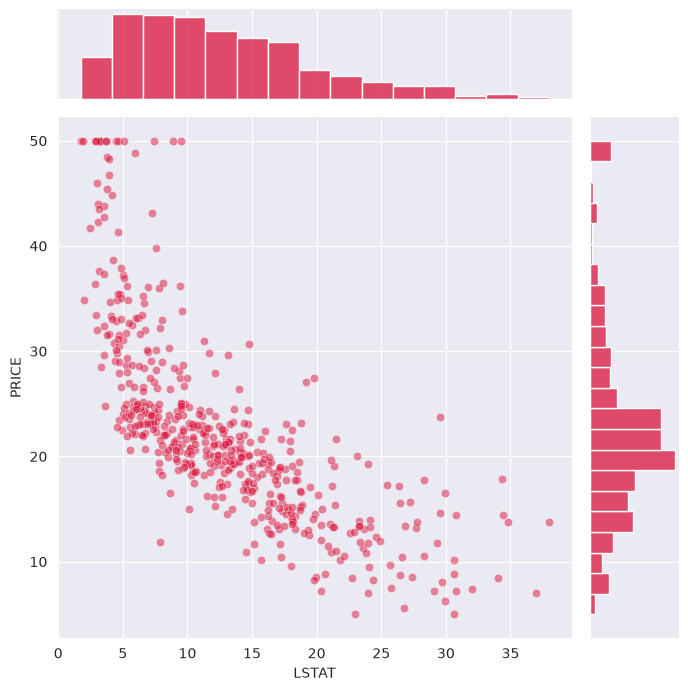

In [18]:
poverty_price_figure(data)

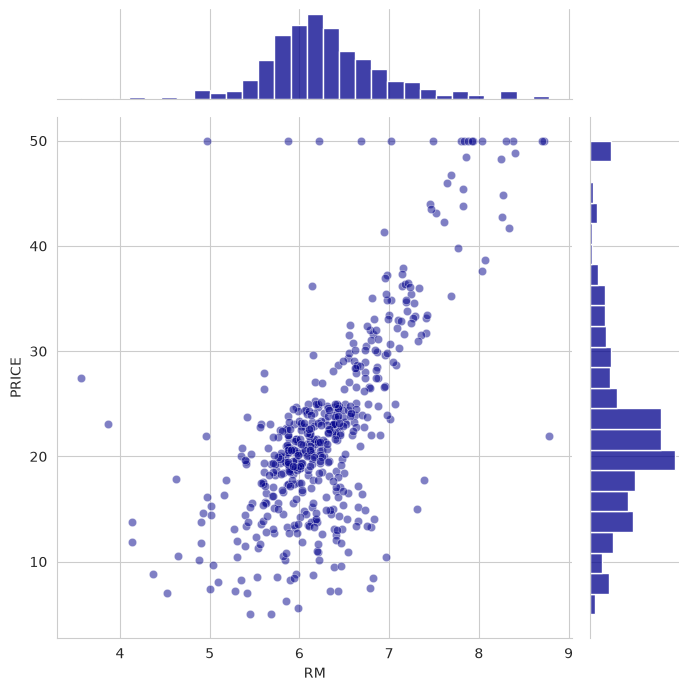

In [19]:
rooms_price_figure(data)

Each observation is backed by a correlation coefficient.

In [20]:
print("DIS vs NOX:", round(relationships.distance_pollution_correlation(data), 2))
print("NOX vs INDUS:", round(relationships.pollution_industry_correlation(data), 2))
print("LSTAT vs RM:", round(relationships.poverty_rooms_correlation(data), 2))
print("LSTAT vs PRICE:", round(relationships.poverty_price_correlation(data), 2))
print("RM vs PRICE:", round(relationships.rooms_price_correlation(data), 2))
relationships.correlation_with_price(data)

DIS vs NOX: -0.77
NOX vs INDUS: 0.76
LSTAT vs RM: -0.61
LSTAT vs PRICE: -0.74
RM vs PRICE: 0.7


LSTAT     -0.737663
RM         0.695360
PTRATIO   -0.507787
INDUS     -0.483725
TAX       -0.468536
NOX       -0.427321
CRIM      -0.388305
RAD       -0.381626
AGE       -0.376955
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
dtype: float64

# Step 4: Split and multivariable regression

Set 20 % of the homes aside (`random_state=10`), fit a linear regression on the other 80 % and read the coefficients and the residuals.

In [21]:
from boston_valuation.domain import regression
from boston_valuation.presentation.regression_charts import (
    actual_vs_predicted_figure,
    residual_distribution_figure,
    residuals_vs_predicted_figure,
)

features, target = regression.split_features_and_target(data)
split = regression.split_train_test(features, target)
train_pct, test_pct = regression.split_percentages(split)
print(f"Training data is {train_pct:.3}% of the total data.")
print(f"Test data makes up the remaining {test_pct:.3}%.")

Training data is 79.8% of the total data.
Test data makes up the remaining 20.2%.


In [22]:
regr = regression.fit_linear_regression(split.x_train, split.y_train)
rsquared = regression.r_squared(regr, split.x_train, split.y_train)
print(f"Training data r-squared: {rsquared:.2}")

Training data r-squared: 0.75


In [23]:
regr_coef = regression.coefficient_table(regr, split.x_train.columns)
regr_coef

,Coefficient
CRIM,-0.128181
ZN,0.063198
INDUS,-0.007576
CHAS,1.974515
NOX,-16.271989
RM,3.108456
AGE,0.016292
DIS,-1.483014
RAD,0.303988
TAX,-0.012082


In [24]:
premium = regression.room_premium(regr_coef)
print(f"The price premium for having an extra room is ${premium:.5}")

The price premium for having an extra room is $3108.5


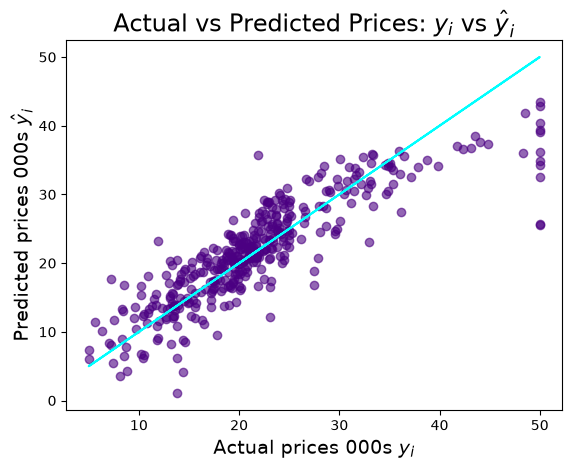

In [25]:
predicted_vals = regression.predictions(regr, split.x_train)
residuals = regression.residuals(split.y_train, predicted_vals)
actual_vs_predicted_figure(split.y_train, predicted_vals)

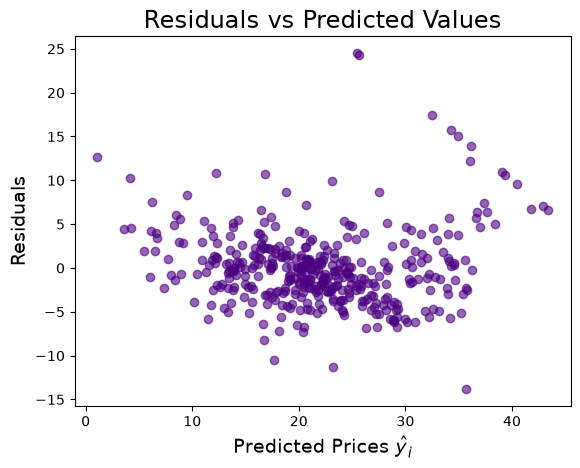

In [26]:
residuals_vs_predicted_figure(predicted_vals, residuals)

Mean: -0.0 Skew: 1.46


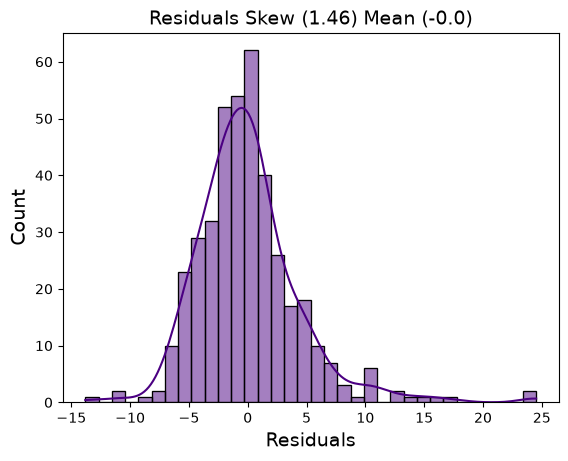

In [27]:
print("Mean:", round(regression.residual_mean(residuals), 2), "Skew:", round(regression.residual_skew(residuals), 2))
residual_distribution_figure(residuals)

# Step 5: The log transformation

The price is skewed to the right and so are the residuals of the first model. Take the natural logarithm of the price, fit the same regression with the same split and compare the two models, first on the training data and then on the test data.

Skew of the price: 1.11
Skew of the log price: -0.33


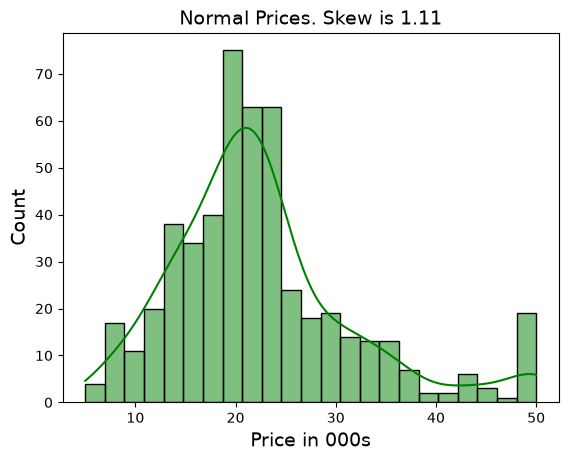

In [28]:
from boston_valuation.domain import log_model
from boston_valuation.presentation.log_charts import (
    log_actual_vs_predicted_figure,
    log_mapping_figure,
    log_price_skew_figure,
    log_residual_distribution_figure,
    log_residuals_vs_predicted_figure,
    model_comparison_panel_figure,
    price_skew_figure,
)

print("Skew of the price:", round(log_model.price_skew(data), 2))
print("Skew of the log price:", round(log_model.log_price_skew(data), 2))
price_skew_figure(data)

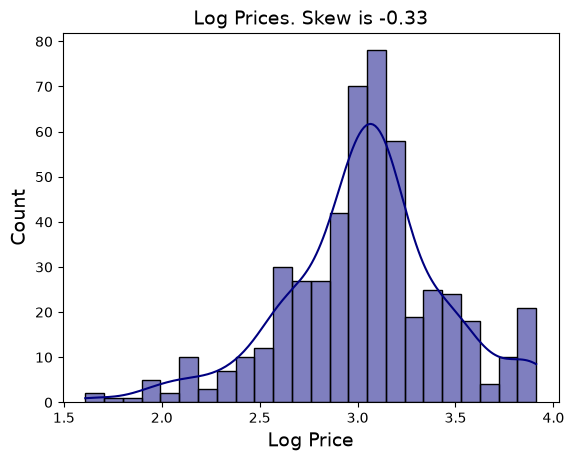

In [29]:
log_price_skew_figure(data)

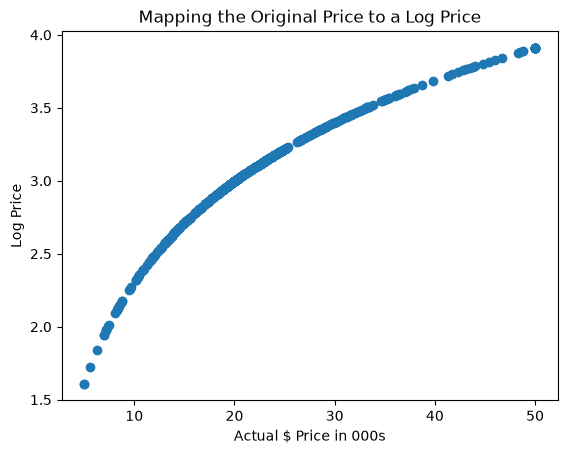

In [30]:
log_mapping_figure(data)

In [31]:
linear = log_model.fit_linear_model(data)
log_fit = log_model.fit_log_model(data)
print(f"Linear model, training r-squared: {linear.train_r_squared:.2}")
print(f"Log model, training r-squared: {log_fit.train_r_squared:.2}")

Linear model, training r-squared: 0.75
Log model, training r-squared: 0.79


In [32]:
log_coef = log_model.log_coefficient_table(log_fit)
print("Expected signs:", log_model.has_expected_signs(log_coef))
log_coef

Expected signs: True


,coef
CRIM,-0.010672
ZN,0.001579
INDUS,0.002030
CHAS,0.080331
NOX,-0.704068
RM,0.073404
AGE,0.000763
DIS,-0.047633
RAD,0.014565
TAX,-0.000645


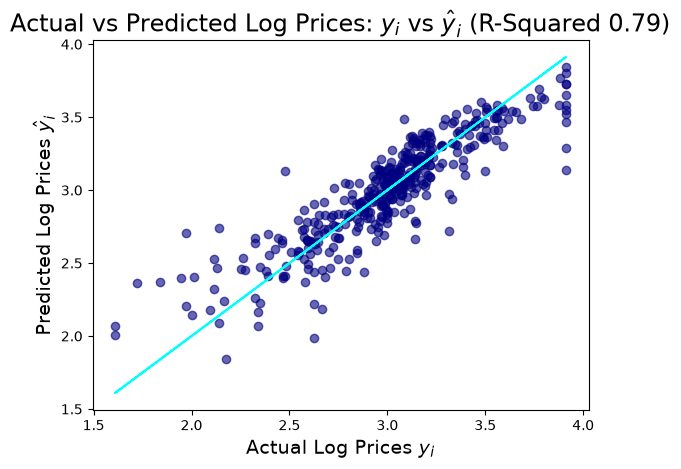

In [33]:
log_actual_vs_predicted_figure(data)

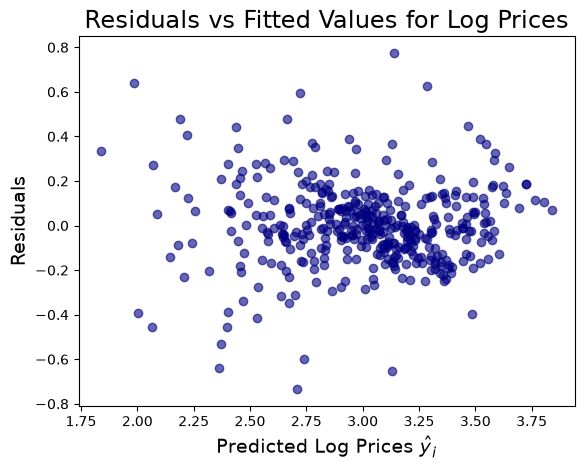

In [34]:
log_residuals_vs_predicted_figure(data)

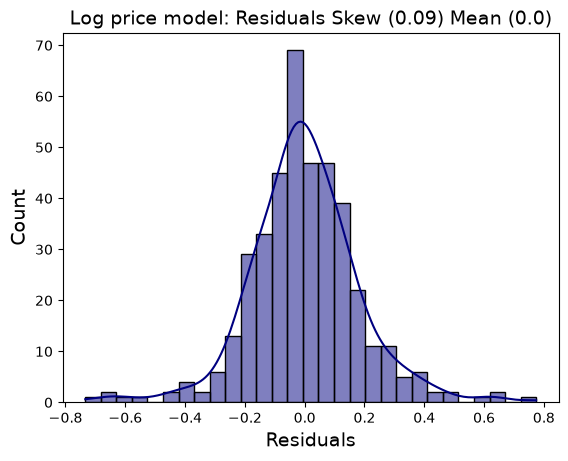

In [35]:
log_residual_distribution_figure(data)

Out of sample: how do the two models score on the homes they have not seen?

In [36]:
scores = log_model.compare_test_r_squared(data)
print(f"Original model test data r-squared: {scores.linear:.2}")
print(f"Log model test data r-squared: {scores.log:.2}")

Original model test data r-squared: 0.67
Log model test data r-squared: 0.74


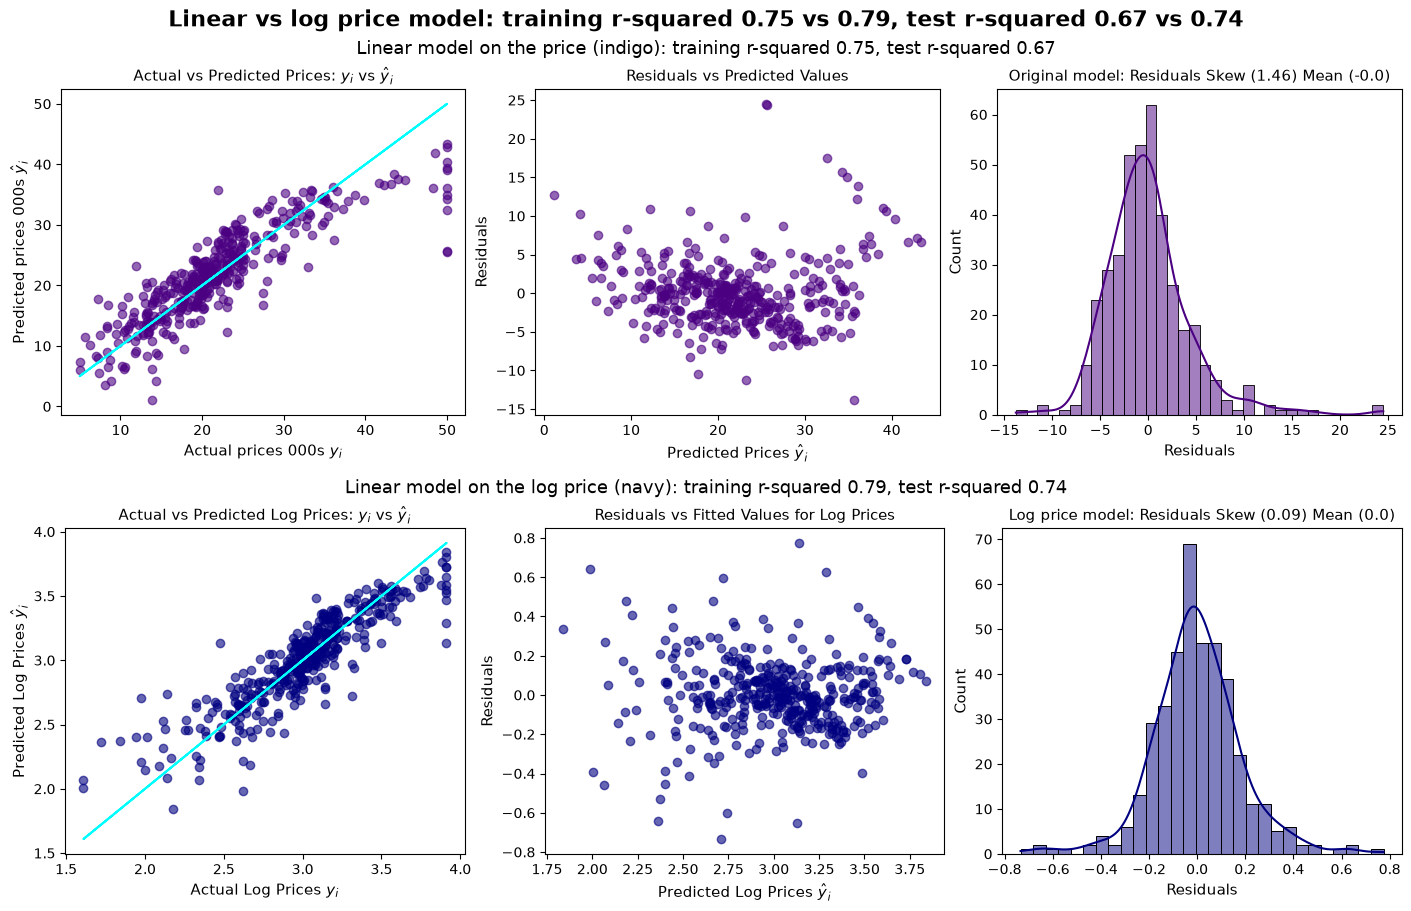

In [37]:
model_comparison_panel_figure(data)

# Step 6: Valuing a property

Use the log model to answer the business question. Start from the average property, then describe a property and value it. The model predicts a log price in thousands of dollars, so `exp` and a factor of 1000 turn it into dollars.

In [38]:
from boston_valuation.domain import log_model, valuation

log_fit = log_model.fit_log_model(data)
property_stats = valuation.average_property(data)
property_stats

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,3.613524,11.363636,11.136779,0.06917,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063


In [39]:
average = valuation.estimate_value(log_fit.model, property_stats)
print(f"The log price estimate is {average.log_estimate:.3}")
print(f"The property is estimated to be worth ${average.dollar_estimate:.6}")

The log price estimate is 3.03
The property is estimated to be worth $20703.2


Now describe a property: next to the river, 8 rooms, 20 students per teacher, a distance of 5, high pollution (75th percentile of `NOX`) and low poverty (25th percentile of `LSTAT`). The other features keep their averages.

In [40]:
described = valuation.value_property(
    data,
    model=log_fit.model,
    next_to_river=True,
    nr_rooms=8,
    students_per_classroom=20,
    distance_to_town=5,
)
print(f"The log price estimate is {described.log_estimate:.3}")
print(f"The property is estimated to be worth ${described.dollar_estimate:.6}")

The log price estimate is 3.25
The property is estimated to be worth $25792.0


In [41]:
valuation.property_characteristics(
    property_stats, valuation.described_property(data)
)

,Average property,Described property
RM,6.284634,8.000
PTRATIO,18.455534,20.000
DIS,3.795043,5.000
CHAS,0.069170,1.000
NOX,0.554695,0.624
LSTAT,12.653063,6.950


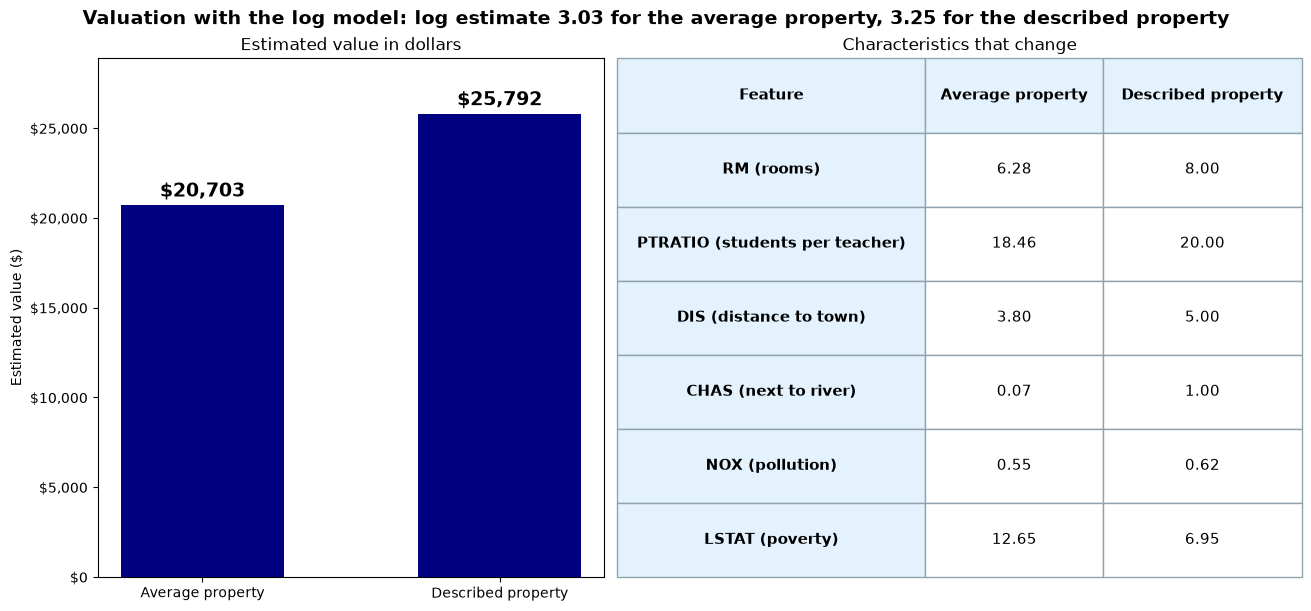

In [42]:
from boston_valuation.presentation.valuation_charts import valuation_figure

valuation_figure(data)

# Step 7: Learning points and summary

The seven learning points of lecture 598 and where this notebook shows them:

1. Spot relationships with a pair plot (step 3).
2. Split the data to judge a model on unseen data (step 4).
3. Run a multivariable regression (step 4).
4. Check the sign of the coefficients (steps 4 and 5).
5. Analyse the residuals (steps 4 and 5).
6. Improve the model with a log transformation (step 5).
7. Predict a price for chosen features (step 6).

The last check compares both models on the training data and on the test data.

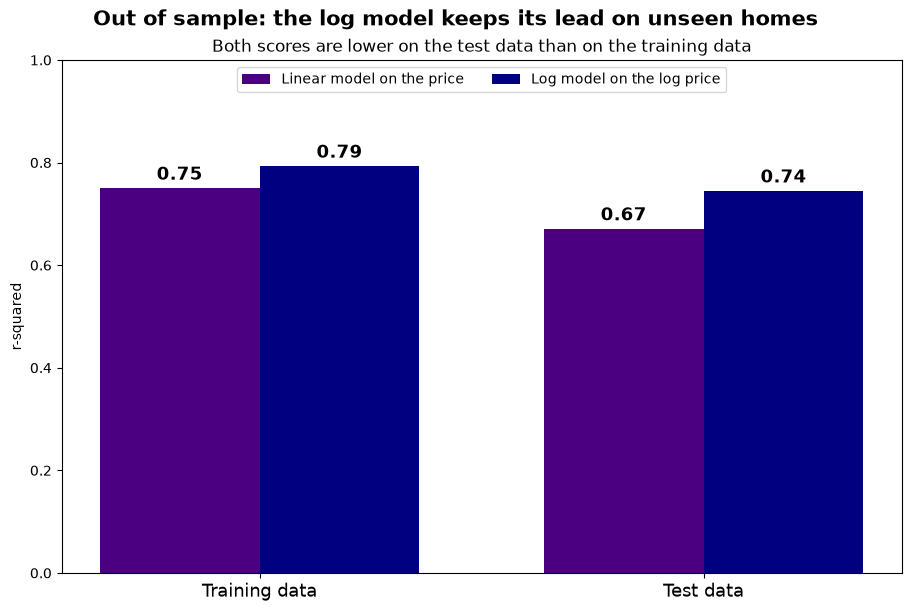

In [43]:
from boston_valuation.presentation.summary_charts import model_scores_figure

model_scores_figure(data)